<a href="https://colab.research.google.com/github/eiyu18/MachineLearning/blob/main/JS09/JS09_Lab05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 7.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520033 sha256=9b26a16d10b6707b5d995f2434437a39ef92bab73391633e49847f726dfbfc9a
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


In [2]:
!pip install faiss-cpu
!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 35.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 MB 41.0 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.2/581.2 MB 13.2 MB/s  0:00:29
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 26.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.3/68.3 MB 24.9 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 MB 23.6 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [faiss-gpu]


In [3]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679801 sha256=ee3b7cdf26f1213451a385797ab2dd28114e313cff92f9c438a3ef273422d640
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


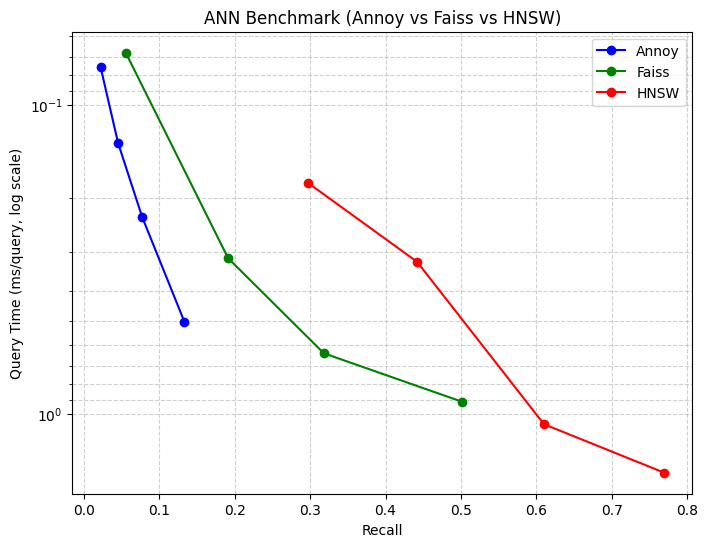

In [4]:
	import numpy as np
	import time
	import faiss
	from annoy import AnnoyIndex
	import hnswlib
	import matplotlib.pyplot as plt

	# -------------------------------
	# Random dataset
	# -------------------------------
	d = 128        # dimension
	nb = 100000    # number of database vectors
	nq = 1000      # number of queries

	np.random.seed(42)
	xb = np.random.random((nb, d)).astype('float32')
	xq = np.random.random((nq, d)).astype('float32')

	# -------------------------------
	# Ground truth with FAISS brute force
	# -------------------------------
	index_flat = faiss.IndexFlatL2(d)
	index_flat.add(xb)
	k = 10
	_, gt_idx = index_flat.search(xq, k)

	# -------------------------------
	# Recall function
	# -------------------------------
	def recall_at_k(I_pred, I_gt, k):
	    correct = 0
	    for i in range(len(I_pred)):
	        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
	    return correct / (len(I_pred) * k)

	# -------------------------------
	# Annoy benchmark
	# -------------------------------
	def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
	    f = xb.shape[1]
	    index = AnnoyIndex(f, 'euclidean')
	    for i, v in enumerate(xb):
	        index.add_item(i, v)
	    index.build(n_trees)

	    start = time.time()
	    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
	    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# FAISS IVF benchmark
	# -------------------------------
	def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
	    quantizer = faiss.IndexFlatL2(d)
	    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
	    index.train(xb)
	    index.add(xb)

	    index.nprobe = nprobe
	    start = time.time()
	    _, I = index.search(xq, k)
	    elapsed = (time.time() - start) * 1000 / len(xq)
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# HNSW benchmark
	# -------------------------------
	def run_hnsw(xb, xq, ef=100, M=16, k=10):
	    num_elements = xb.shape[0]
	    p = hnswlib.Index(space='l2', dim=d)
	    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
	    p.add_items(xb)
	    p.set_ef(ef)

	    start = time.time()
	    I, _ = p.knn_query(xq, k)
	    elapsed = (time.time() - start) * 1000 / len(xq)
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# Run benchmark with several parameters
	# -------------------------------
	results = {"Annoy": [], "Faiss": [], "HNSW": []}

	# Annoy
	for sk in [200, 500, 1000, 2000]:
	    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
	    results["Annoy"].append((rec, t))

	# FAISS
	for npb in [1, 5, 10, 20]:
	    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
	    results["Faiss"].append((rec, t))

	# HNSW
	for ef in [50, 100, 200, 400]:
	    rec, t = run_hnsw(xb, xq, ef=ef)
	    results["HNSW"].append((rec, t))

	# -------------------------------
	# Visualize the trade-off
	# -------------------------------
	plt.figure(figsize=(8,6))
	for label, color in zip(results.keys(), ["blue","green","red"]):
	    recall, qtime = zip(*results[label])
	    plt.plot(recall, qtime, marker="o", label=label, color=color)

	plt.xlabel("Recall")
	plt.ylabel("Query Time (ms/query, log scale)")
	plt.yscale("log")
	plt.gca().invert_yaxis()  # invert Y, the more to the right the lower
	plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
	plt.legend()
	plt.grid(True, which="both", ls="--", alpha=0.6)
	plt.show()